In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("../data/IMDB Dataset.csv")

# Display the first five rows
df.head()

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
print("Dataset loaded successfully!")

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset loaded successfully!
Dataset shape: (50000, 2)

Column names:
Index(['review', 'sentiment'], dtype='str')

Sentiment distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [3]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicate reviews
print("\nDuplicate rows:", df.duplicated().sum())

# Check dataset information
print("\nDataset information:")
df.info()

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows: 418

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [4]:
# Display one positive review
print("POSITIVE REVIEW:\n")
print(df[df["sentiment"] == "positive"]["review"].iloc[0])

print("\n" + "=" * 80)

# Display one negative review
print("\nNEGATIVE REVIEW:\n")
print(df[df["sentiment"] == "negative"]["review"].iloc[0])

POSITIVE REVIEW:

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show

In [5]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nDataset information:")
df.info()

Missing values:
review       0
sentiment    0
dtype: int64

Duplicate rows:
418

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [6]:
# Calculate the number of characters in each review
df["review_length"] = df["review"].apply(len)

print("Review length statistics:")
print(df["review_length"].describe())

Review length statistics:
count    50000.000000
mean      1309.431020
std        989.728014
min         32.000000
25%        699.000000
50%        970.000000
75%       1590.250000
max      13704.000000
Name: review_length, dtype: float64


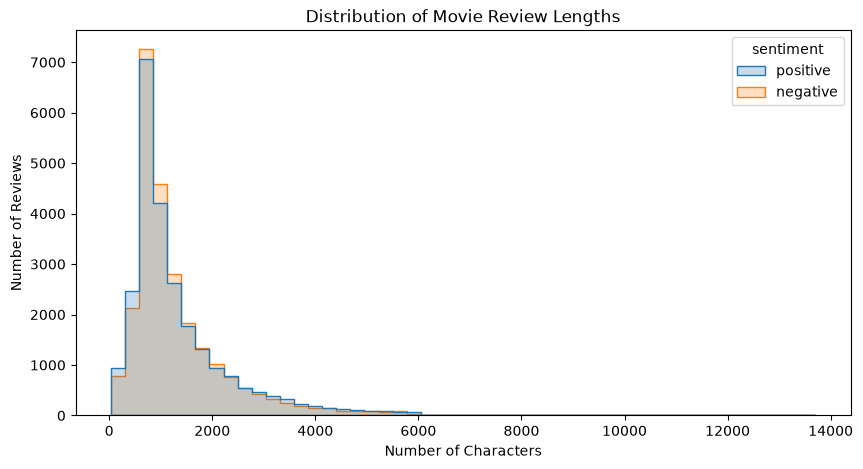

In [7]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="review_length",
    hue="sentiment",
    bins=50,
    element="step"
)

plt.title("Distribution of Movie Review Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")

plt.show()

In [8]:
# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

Dataset shape after removing duplicates: (49582, 3)

Sentiment distribution:
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


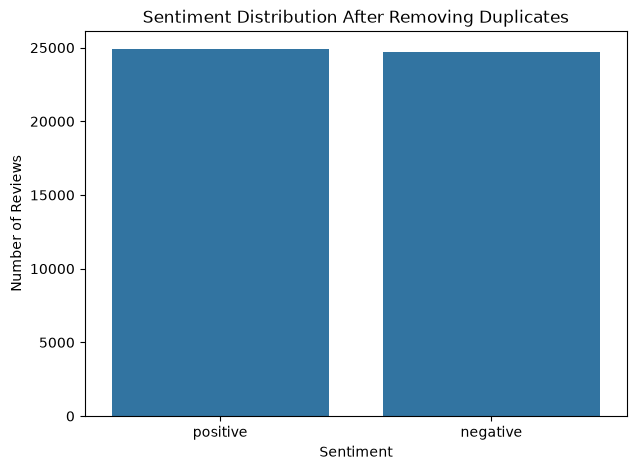

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="sentiment"
)

plt.title("Sentiment Distribution After Removing Duplicates")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [10]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

# Load the original dataset
df = pd.read_csv("../data/IMDB Dataset.csv")

# Remove duplicate rows
df = df.drop_duplicates()

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (49582, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [11]:
def clean_html(text):
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [12]:
sample_review = df["review"][1]

print("Before cleaning:")
print(sample_review[:500])

print("\nAfter cleaning:")
print(clean_html(sample_review)[:500])

Before cleaning:
A wonderful little production. <br /><br />The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. <br /><br />The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrificly writte

After cleaning:
A wonderful little production. The filming technique is very unassuming- very old-time-BBC fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. The actors are extremely well chosen- Michael Sheen not only "has got all the polari" but he has all the voices down pat too! You can truly see the seamless editing guided by the references to Williams' diary entries, not only is it well worth the watching but it is a terrif

In [13]:
# Apply HTML cleaning to all reviews
df["cleaned_review"] = df["review"].apply(clean_html)

print("HTML cleaning completed!")

# Display original and cleaned reviews
df[["review", "cleaned_review"]].head()

HTML cleaning completed!


,review,cleaned_review
0,One of the other reviewers has mentioned that ...,One of the other reviewers has mentioned that ...
1,A wonderful little production. <br /><br />The...,A wonderful little production. The filming tec...
2,I thought this was a wonderful way to spend ti...,I thought this was a wonderful way to spend ti...
3,Basically there's a family where a little boy ...,Basically there's a family where a little boy ...
4,"Petter Mattei's ""Love in the Time of Money"" is...","Petter Mattei's ""Love in the Time of Money"" is..."


In [14]:
# Check for remaining HTML tags
html_tags = df["cleaned_review"].str.contains(
    r"<[^>]+>",
    regex=True
).sum()

print("Reviews containing HTML tags:", html_tags)

Reviews containing HTML tags: 0


In [15]:
# Convert all cleaned reviews to lowercase
df["cleaned_review"] = df["cleaned_review"].str.lower()

print("Lowercase conversion completed!")

# Display sample reviews
df[["cleaned_review", "sentiment"]].head()

Lowercase conversion completed!


,cleaned_review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production. the filming tec...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there's a family where a little boy ...,negative
4,"petter mattei's ""love in the time of money"" is...",positive


In [16]:
sample_text = df["cleaned_review"][1]

print("Sample cleaned review:")
print(sample_text[:500])

print("\nIs everything lowercase?")
print(sample_text == sample_text.lower())

Sample cleaned review:
a wonderful little production. the filming technique is very unassuming- very old-time-bbc fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. the actors are extremely well chosen- michael sheen not only "has got all the polari" but he has all the voices down pat too! you can truly see the seamless editing guided by the references to williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. a

Is everything lowercase?
True


In [17]:
def remove_special_characters(text):
    # Keep only lowercase letters, numbers and whitespace
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text)

    return text.strip()

In [18]:
sample_text = df["cleaned_review"][1]

print("Before:")
print(sample_text[:500])

print("\nAfter:")
print(remove_special_characters(sample_text)[:500])

Before:
a wonderful little production. the filming technique is very unassuming- very old-time-bbc fashion and gives a comforting, and sometimes discomforting, sense of realism to the entire piece. the actors are extremely well chosen- michael sheen not only "has got all the polari" but he has all the voices down pat too! you can truly see the seamless editing guided by the references to williams' diary entries, not only is it well worth the watching but it is a terrificly written and performed piece. a

After:
a wonderful little production the filming technique is very unassuming very old time bbc fashion and gives a comforting and sometimes discomforting sense of realism to the entire piece the actors are extremely well chosen michael sheen not only has got all the polari but he has all the voices down pat too you can truly see the seamless editing guided by the references to williams diary entries not only is it well worth the watching but it is a terrificly written and performed pi

In [19]:
# Remove punctuation and special characters from all reviews
df["cleaned_review"] = df["cleaned_review"].apply(
    remove_special_characters
)

print("Special character cleaning completed!")

# Display sample cleaned reviews
df[["cleaned_review", "sentiment"]].head()

Special character cleaning completed!


,cleaned_review,sentiment
0,one of the other reviewers has mentioned that ...,positive
1,a wonderful little production the filming tech...,positive
2,i thought this was a wonderful way to spend ti...,positive
3,basically there s a family where a little boy ...,negative
4,petter mattei s love in the time of money is a...,positive


In [20]:
# Check for remaining special characters
special_characters = df["cleaned_review"].str.contains(
    r"[^a-z0-9\s]",
    regex=True
).sum()

print("Reviews containing special characters:", special_characters)

Reviews containing special characters: 0
